# B04-DB — DBSCAN trên RFM (log1p + MinMax + PCA 90%)

Thí nghiệm **B04-DB** (người chạy: Nguyên) theo chiến lược model. So với B01, **chỉ thay StandardScaler bằng MinMaxScaler**: làm sạch → RFM → `log1p` → MinMaxScaler → PCA giữ ≥ 90% phương sai → DBSCAN. Mục đích: đo riêng tác động của scaler trong nhánh B.

Quy tắc chọn cấu hình giữ nguyên như A01-DB (An): ≥ 2 cụm, nhiễu ≤ 5%, Silhouette cao nhất. B01-DB chưa có trong repo nên được dựng lại ngay trong notebook để so cùng điều kiện. Một chỗ **phải khác**: thang của `eps` (xem phần k-distance).

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.90                      # giữ ít nhất 90% phương sai (giống A01, B01)
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]                       # giống A01-DB
EPS_GRID_STD = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # lưới eps gốc của A01-DB (đơn vị Standard)
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A04-DB, B01-GN), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, 3 biến RFM, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). Đây là file làm sạch cũ của nhóm, không phải RFM tính thẳng từ raw (chi tiết ở A02-KM); các thí nghiệm cùng dùng file này nên so sánh được với nhau.

## `log1p`, MinMaxScaler và PCA giữ 90% phương sai

B04 dùng MinMax (mọi biến về [0, 1]); đồng thời dựng không gian B01 (Standard) để làm mốc so sánh.

In [3]:
Xl = np.log1p(X)

def pca90(Xs):
    cum = np.cumsum(PCA(svd_solver="full").fit(Xs).explained_variance_ratio_)
    n = int(np.searchsorted(cum, PCA_VAR) + 1)
    return PCA(n_components=n, svd_solver="full").fit_transform(Xs), cum, n

Z, cum, n_pc = pca90(MinMaxScaler().fit_transform(Xl))             # B04
Z_b01, cum_b01, n_pc_b01 = pca90(StandardScaler().fit_transform(Xl))   # B01 dựng lại

print("B04 (MinMax)  — phương sai tích lũy:", cum.round(4), f"| số PC giữ lại: {n_pc}/3")
print("B01 (Standard) — phương sai tích lũy:", cum_b01.round(4), f"| số PC giữ lại: {n_pc_b01}/3")

B04 (MinMax)  — phương sai tích lũy: [0.7901 0.9697 1.    ] | số PC giữ lại: 2/3
B01 (Standard) — phương sai tích lũy: [0.7536 0.9401 1.    ] | số PC giữ lại: 2/3


**Nhận xét:** Cả hai scaler đều cần **2 PC** để vượt 90%: MinMax giữ 79,01% + 17,96% = 96,97%, Standard giữ 94,01%. PCA ở nhánh B thực sự giảm chiều từ 3 xuống 2 (khác A01/A04 nơi PCA chỉ xoay trục).

## Chọn eps bằng đồ thị k-distance và quy đổi thang eps

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó), sắp xếp tăng dần. MinMax nén mọi biến vào [0, 1] nên khoảng cách nhỏ hơn nhiều so với Standard; lưới eps gốc của A01-DB (0,1–2,0) sẽ không còn ý nghĩa ở thang này, cần quy đổi.

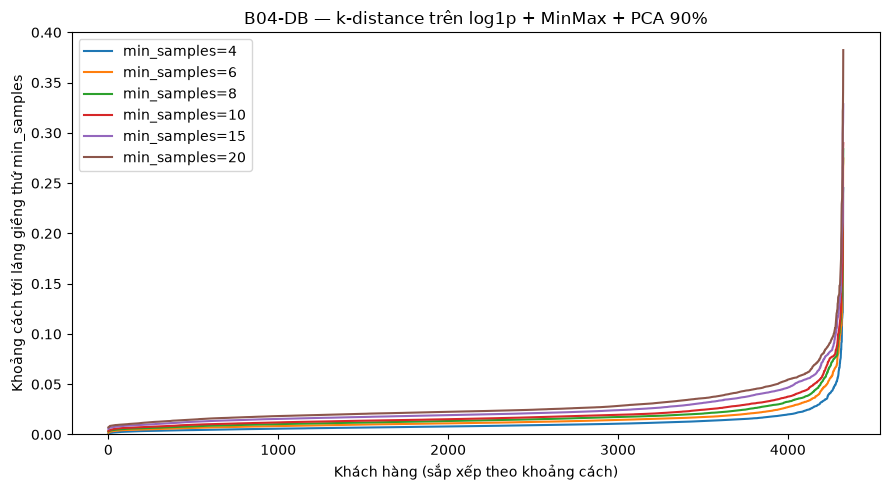

Hệ số quy đổi thang eps (MinMax / Standard) = 0.160
Lưới eps cho B04: [0.016, 0.032, 0.048, 0.064, 0.08, 0.112, 0.16, 0.24, 0.32]

k-distance B04 (MinMax):
        4      6      8      10     15     20
P50  0.008  0.011  0.014  0.016  0.020  0.023
P90  0.018  0.023  0.029  0.033  0.042  0.048
P95  0.024  0.033  0.038  0.044  0.055  0.061
P99  0.051  0.067  0.077  0.084  0.101  0.114

k-distance B01 (Standard):
        4      6      8      10     15     20
P50  0.051  0.067  0.079  0.090  0.113  0.132
P90  0.108  0.137  0.162  0.183  0.228  0.269
P95  0.151  0.194  0.230  0.258  0.317  0.361
P99  0.320  0.401  0.453  0.547  0.630  0.722


In [4]:
def kdist(Zs):
    d = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(Zs).kneighbors(Zs)[0][:, -1]) for ms in MIN_SAMPLES_GRID}
    q = pd.DataFrame({ms: np.quantile(v, [0.5, 0.9, 0.95, 0.99]) for ms, v in d.items()}, index=["P50", "P90", "P95", "P99"])
    return d, q

kd, q_b04 = kdist(Z)
_, q_b01 = kdist(Z_b01)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kd.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 0.4)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("B04-DB — k-distance trên log1p + MinMax + PCA 90%")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

# Hệ số quy đổi: tỷ số P99 của k-distance (MinMax / Standard), trung vị qua các min_samples
scale = float(np.median([q_b04.loc["P99", ms] / q_b01.loc["P99", ms] for ms in MIN_SAMPLES_GRID]))
EPS_GRID_B04 = [round(e * scale, 3) for e in EPS_GRID_STD]
print(f"Hệ số quy đổi thang eps (MinMax / Standard) = {scale:.3f}")
print("Lưới eps cho B04:", EPS_GRID_B04)
print("\nk-distance B04 (MinMax):"); print(q_b04.round(3).to_string())
print("\nk-distance B01 (Standard):"); print(q_b01.round(3).to_string())

In [5]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Zs), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Zs[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Zs[mask], labels[mask]), 4)
    return row, labels

def run_grid(Zs, eps_grid):
    pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in eps_grid]
    out = [run_dbscan(Zs, e, m) for e, m in pairs]
    return pd.DataFrame([r for r, _ in out]), {p: l for p, (_, l) in zip(pairs, out)}

def select(g):
    # ≥ 2 cụm, nhiễu ≤ 5%, Silhouette cao nhất; hòa thì lấy cấu hình đứng trước trong lưới
    valid = g[(g["n_clusters"] >= MIN_CLUSTERS) & (g["noise_pct"] <= MAX_NOISE * 100)]
    return valid.sort_values("silhouette", ascending=False, kind="stable").iloc[0]

# Kiểm tra: lưới eps GỐC đặt vào không gian MinMax
g_orig, _ = run_grid(Z, EPS_GRID_STD)
print("Lưới eps gốc trên MinMax — số cấu hình có >= 2 cụm:", int((g_orig["n_clusters"] >= 2).sum()), "/", len(g_orig))
print("Lưới eps gốc trên MinMax — số cấu hình chỉ 1 cụm:", int((g_orig["n_clusters"] == 1).sum()))

Lưới eps gốc trên MinMax — số cấu hình có >= 2 cụm: 1 / 54
Lưới eps gốc trên MinMax — số cấu hình chỉ 1 cụm: 53


**Nhận xét:** Ở MinMax, khoảng cách tới láng giềng nhỏ hơn Standard khoảng 6 lần: P99 của k-distance chỉ 0,05–0,11 (min_samples 4–20) so với 0,32–0,72 ở B01, nên hệ số quy đổi ≈ 0,16. Đặt nguyên lưới eps gốc vào MinMax thì **53/54 cấu hình chỉ cho 1 cụm** — lưới không còn phủ vùng cần quét. Vì vậy B04 dùng **cùng lưới nhưng nhân với 0,16** (0,016–0,32), để so cùng "vị trí tương đối" với B01; quy tắc chọn không đổi.

## Quét lưới eps × min_samples (B04)

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [6]:
grid, lab_b04 = run_grid(Z, EPS_GRID_B04)
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
print("Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách:",
      int(((grid["n_clusters"] >= 2) & (grid["largest_pct"] < 90)).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(8)

Số cấu hình đã chạy: 54
Số cấu hình có >= 2 cụm: 24
Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách: 12


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
5,4,0.112,2,0.07,99.77,7,0.6001,0.3357
14,6,0.112,2,0.07,99.77,7,0.6001,0.3357
4,4,0.080,2,0.21,99.70,4,0.5847,0.3163
45,20,0.016,12,75.36,14.21,11,0.4586,0.5790
3,4,0.064,3,0.42,98.82,4,0.4033,0.5177
21,8,0.064,2,1.11,98.59,13,0.3904,0.4712
20,8,0.048,2,2.24,95.59,94,0.3781,0.7031
12,6,0.064,3,0.67,98.68,7,0.3719,0.5218


**Nhận xét:** 24/54 cấu hình có ≥ 2 cụm. 12 cấu hình có một cụm chiếm ≥ 93,7% khách — đây là kiểu "tách ngoại lai". 12 cấu hình còn lại chia khối chính đều hơn (cụm lớn nhất < 90%), nhưng 9 trong số đó bị loại vì nhiễu > 5% (cao nhất là min_samples = 20, eps = 0,016: 12 cụm nhưng 75% khách bị gán nhiễu). Ba cấu hình ở eps = 0,032 (min_samples 4, 6, 8) chia khối chính thành 12–20 cụm với nhiễu chỉ 1,9–4,9% nên **qua** điều kiện nhiễu, nhưng Silhouette chỉ −0,04 đến 0,23, thấp hơn nhiều so với kiểu tách ngoại lai (0,60), nên quy tắc "Silhouette lớn nhất" không chọn chúng.

## Chọn cấu hình

Cùng quy tắc A01-DB (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, **Silhouette cao nhất**.

In [7]:
best = select(grid)
print("Cấu hình được chọn:")
print(best.to_string())

Cấu hình được chọn:
min_samples     4.0000
eps             0.1120
n_clusters      2.0000
noise_pct       0.0700
largest_pct    99.7700
smallest        7.0000
silhouette      0.6001
dbi             0.3357


**Nhận xét:** Chọn `min_samples = 4`, `eps = 0,112`: 2 cụm, nhiễu 0,07% (3 khách), cụm lớn nhất 99,77%, cụm còn lại chỉ 7 khách; Silhouette 0,6001, DBI 0,3357. Hai cấu hình (`min_samples` = 4 và 6, cùng eps 0,112) cho cùng mọi chỉ số; quy tắc hòa lấy cấu hình đứng trước. Silhouette cao vì một khối 99,8% khách nằm cách xa 7 khách ngoại lai, không phải vì phân khúc tốt.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary của nhóm.

In [8]:
labels = lab_b04[(float(best["eps"]), int(best["min_samples"]))]
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")
prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,3,39.0,51.0,34684.4,0.1,1.3
0,4317,51.0,2.0,657.2,99.8,88.4
1,7,2.0,97.0,60632.8,0.2,10.3


**Nhận xét:** Cụm 0 (4.317 khách, 99,8%) có Recency 51, Frequency 2, Monetary 657,2 — đúng bằng trung vị toàn bộ khách — và đóng góp 88,4% Monetary. Cụm 1 chỉ 7 khách (0,2%): Recency 2, Frequency 97, Monetary ≈ 60.633, chiếm 10,3% Monetary. 3 khách nhiễu (Recency 39, Frequency 51, Monetary ≈ 34.684) có hồ sơ gần nhóm ngoại lai hơn khối chính. Tức là chỉ một nhóm cỡ chục khách ngoại lai được tách ra.

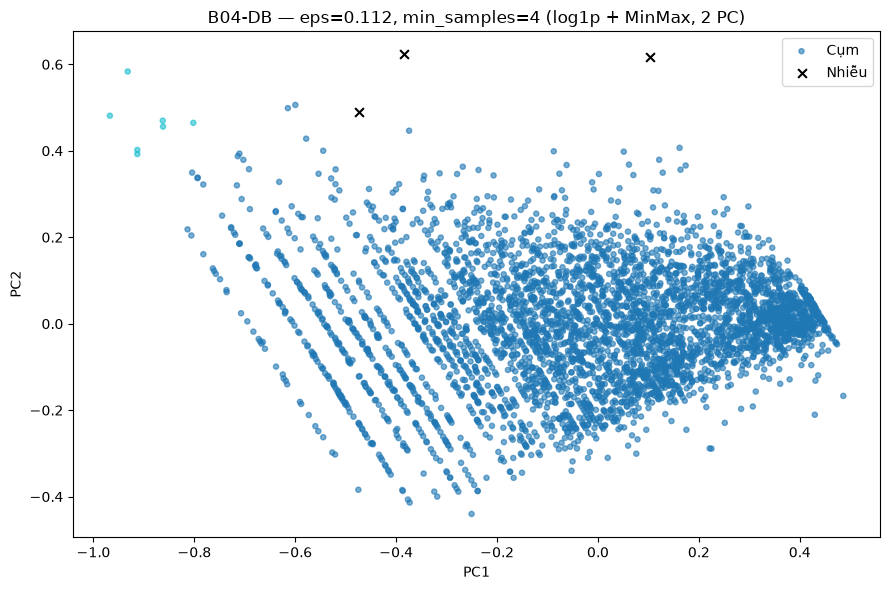

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=40, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"B04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (log1p + MinMax, {n_pc} PC)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Toàn bộ khách dồn thành một khối liền ở góc dưới; 7 khách của cụm 1 và 3 điểm nhiễu nằm rải ở phần đuôi xa. Hình xác nhận DBSCAN chỉ tách phần đuôi ngoại lai, kể cả sau `log1p`.

## Đối chiếu B01 (dựng lại cùng điều kiện)

Dựng lại B01-DB (`log1p` → StandardScaler → PCA 90% → DBSCAN) với **lưới eps gốc** của A01-DB và cùng quy tắc chọn. So từng ô của lưới theo vị trí tương đối (eps B04 = eps B01 × hệ số quy đổi) và so cấu hình được chọn của mỗi bên.

In [10]:
grid_b01, lab_b01 = run_grid(Z_b01, EPS_GRID_STD)
best_b01 = select(grid_b01)
labels_b01 = lab_b01[(float(best_b01["eps"]), int(best_b01["min_samples"]))]
print(f"B01 dựng lại: {n_pc_b01}/3 PC | số cấu hình có >= 2 cụm: {int((grid_b01['n_clusters'] >= 2).sum())}/{len(grid_b01)}")
print("B01 được chọn:", best_b01[["min_samples", "eps", "n_clusters", "noise_pct", "largest_pct", "smallest",
                                  "silhouette", "dbi"]].to_dict())
print("Hồ sơ cụm B01:"); print(profile(labels_b01).round(1).to_string())

ari_sel = adjusted_rand_score(labels, labels_b01)
matched = [adjusted_rand_score(lab_b01[(e1, m)], lab_b04[(e4, m)])
           for m in MIN_SAMPLES_GRID for e1, e4 in zip(EPS_GRID_STD, EPS_GRID_B04)]
n_ident, med_ari, min_ari = sum(a == 1.0 for a in matched), float(np.median(matched)), float(min(matched))
print(f"\nARI giữa hai cấu hình được chọn: {ari_sel:.4f}")
print(f"ARI theo từng ô lưới tương ứng: giống hệt {n_ident}/{len(matched)} ô | trung vị {med_ari:.4f} | nhỏ nhất {min_ari:.4f}")

B01 dựng lại: 2/3 PC | số cấu hình có >= 2 cụm: 18/54
B01 được chọn: {'min_samples': 4.0, 'eps': 0.5, 'n_clusters': 2.0, 'noise_pct': 0.18, 'largest_pct': 99.68, 'smallest': 6.0, 'silhouette': 0.6579, 'dbi': 0.2753}
Hồ sơ cụm B01:
         customers  Recency  Frequency  Monetary  customer_share_pct  Monetary_share_pct
cluster                                                                                 
-1               8     32.0       40.0   94634.1                 0.2                 7.7
 0            4313     51.0        2.0     657.2                99.7                83.6
 1               6      1.5       94.0   59697.4                 0.1                 8.7

ARI giữa hai cấu hình được chọn: 0.7487
ARI theo từng ô lưới tương ứng: giống hệt 12/54 ô | trung vị 0.6383 | nhỏ nhất -0.0003


In [11]:
def line(name, scaler, n_components, g_row, lab, eps_grid_note):
    sizes = pd.Series(lab[lab != -1]).value_counts().tolist()
    return {"Thí nghiệm": name, "Scaler": scaler, "Số PC": n_components, "Lưới eps": eps_grid_note,
            "eps": float(g_row["eps"]), "min_samples": int(g_row["min_samples"]), "Số cụm": int(g_row["n_clusters"]),
            "Nhiễu (khách)": int((lab == -1).sum()), "Nhiễu (%)": float(g_row["noise_pct"]),
            "Cụm lớn nhất (%)": float(g_row["largest_pct"]), "Silhouette": float(g_row["silhouette"]),
            "DBI": float(g_row["dbi"]), "Kích thước cụm": sizes}

cmp = pd.DataFrame([
    line("B04-DB", "log1p + MinMax", n_pc, best, labels, "eps gốc × 0,16"),
    line("B01-DB (dựng lại)", "log1p + Standard", n_pc_b01, best_b01, labels_b01, "eps gốc"),
])
cmp

,Thí nghiệm,Scaler,Số PC,Lưới eps,eps,min_samples,Số cụm,Nhiễu (khách),Nhiễu (%),Cụm lớn nhất (%),Silhouette,DBI,Kích thước cụm
0,B04-DB,log1p + MinMax,2,"eps gốc × 0,16",0.112,4,2,3,0.07,99.77,0.6001,0.3357,"[4317, 7]"
1,B01-DB (dựng lại),log1p + Standard,2,eps gốc,0.500,4,2,8,0.18,99.68,0.6579,0.2753,"[4313, 6]"


**Nhận xét:**
- **Cùng bức tranh định tính:** cả hai chọn 2 cụm, và cụm phụ chỉ có 6–7 khách với Frequency 94–97, Monetary ≈ 60.000 (B01: cụm 1 gồm 6 khách, 8 khách nhiễu; B04: cụm 1 gồm 7 khách, 3 khách nhiễu); 99,7–99,8% khách ở một khối với hồ sơ bằng trung vị toàn bộ.
- **Khác ở chi tiết:** ARI giữa hai cấu hình được chọn là 0,7487; theo từng ô lưới tương ứng chỉ 12/54 ô cho cách chia giống hệt, trung vị ARI 0,638. MinMax và Standard đặt ranh giới "nhiễu" ở chỗ khác nhau (B01 gán 8 khách nhiễu, B04 gán 3), nhưng không tạo ra cấu trúc cụm mới.
- **Số cấu hình có ≥ 2 cụm nhiều hơn một chút ở B04** (24/54 so với 18/54 ở B01), song các cấu hình chia khối chính đều hơn vẫn không được chọn: hoặc nhiễu quá cao, hoặc Silhouette thấp (≈ 0,23) so với kiểu tách ngoại lai (0,60).
- **Không so Silhouette trực tiếp** (0,6001 so với 0,6579): hai giá trị tính trên hai không gian khác nhau và đều do tách vài khách ngoại lai; chúng không phản ánh chất lượng phân khúc.

## Lưu kết quả

In [12]:
grid.to_csv(OUT / "dbscan_b04_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_b04_labels.csv", index=False)
params = {"experiment": "B04-DB", "features": FEATURES, "transform": "log1p", "scaler": "MinMaxScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "eps_scale_vs_standard": round(scale, 4),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "ari_vs_b01_selected": round(float(ari_sel), 4)}
json.dump(params, open(OUT / "dbscan_b04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_b04_grid.csv', 'dbscan_b04_labels.csv', 'dbscan_b04_params.json']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng cấu hình, bảng cụm), chuyển các cột cho DBSCAN, thêm bảng đối chiếu B01.

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "DBSCAN_B04"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

e_best, m_best = float(best["eps"]), int(best["min_samples"])
put("A1", "THÍ NGHIỆM DBSCAN — B04 (RFM, log1p, MinMax, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; Silhouette/DBI tính trên khách không bị gán nhiễu, trong không gian đã fit")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", f"Z (log1p → MinMax → PCA 90%, {n_pc} PC)"),
        ("eps được chọn", e_best), ("min_samples được chọn", m_best),
        ("Quy tắc chọn", "≥ 2 cụm, nhiễu ≤ 5%, Silhouette lớn nhất"),
        ("Lưới", f"{len(EPS_GRID_B04)} eps × {len(MIN_SAMPLES_GRID)} min_samples = {len(grid)}")]
right = [("PCA", f"90% → {n_pc}/3 PC (phương sai {cum[n_pc-1]:.2%})"), ("Tổng khách hàng", int(len(X))),
         ("Số cụm (không tính nhiễu)", int(best["n_clusters"])), ("Nhiễu (%)", float(best["noise_pct"])),
         ("Thang eps", f"lưới gốc A01-DB × {scale:.2f} (do MinMax)"),
         ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

hdr = ["min_samples", "eps", "Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)", "Cụm nhỏ nhất (khách)", "Silhouette", "DBI", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(f"{c}12", v, bold=True)
multi = grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False, kind="stable")
for i, r in enumerate(multi.itertuples(), start=13):
    if r.eps == e_best and r.min_samples == m_best: note = "cấu hình được chọn"
    elif r.noise_pct > MAX_NOISE * 100: note = "loại: nhiễu > 5%"
    else: note = ""
    if r.silhouette < 0: note = (note + "; " if note else "") + "Silhouette âm (chia vụn)"
    vals = [int(r.min_samples), float(r.eps), int(r.n_clusters), float(r.noise_pct), float(r.largest_pct),
            int(r.smallest), float(r.silhouette), float(r.dbi), note]
    fmts = [None, "0.000", None, "0.00", "0.00", None, "0.0000", "0.0000", None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(f"{c}{i}", v, fmt=f)
put(f"A{13 + len(multi)}", f"Chỉ liệt kê {len(multi)}/{len(grid)} cấu hình có ≥ 2 cụm; các cấu hình còn lại chỉ có 1 cụm.")

r0 = 13 + len(multi) + 3
for c, v in zip("ABCDEFGH", ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)",
                              "Frequency (median)", "Monetary (median)", "Tỷ trọng Monetary (%)"]):
    put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Nhiễu (ngoại lai)" if cl == -1 else "Khối chính" if p["customers"] == prof["customers"].max() else "Cụm nhỏ")
    put(f"A{j}", int(cl)); put(f"B{j}", nhom); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu B01-DB (dựng lại, lưới eps gốc, StandardScaler)", bold=True)
for c, v in zip("ABCDEFGH", ["Thí nghiệm", "Scaler", "eps", "min_samples", "Số cụm", "Nhiễu (khách)", "Silhouette", "DBI"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], r[4], r[5], r[6], r[7], r[10], r[11]]
    for c, v, f in zip("ABCDEFGH", vals, [None, None, "0.000", None, None, None, "0.0000", "0.0000"]):
        put(f"{c}{j}", v, fmt=f)
put(f"A{r1+5}", f"ARI giữa hai cấu hình được chọn: {ari_sel:.4f}")
put(f"A{r1+6}", f"Theo từng ô lưới tương ứng: giống hệt {n_ident}/{len(matched)} ô; ARI trung vị {med_ari:.3f}")
put(f"A{r1+7}", "Silhouette/DBI của hai thí nghiệm tính trên hai không gian khác nhau và đều do tách vài khách ngoại lai, không so trực tiếp.")

for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_DBSCAN_B04.xlsx")
print("Đã lưu Working_details_DBSCAN_B04.xlsx")

Đã lưu Working_details_DBSCAN_B04.xlsx


## Kết luận B04-DB

- **Đổi scaler không đổi bức tranh DBSCAN:** cấu hình được chọn của B04 (eps 0,112, min_samples 4) và của B01 dựng lại (eps 0,5, min_samples 4) đều chỉ tách 6–7 khách ngoại lai (Frequency ≈ 95, Monetary ≈ 60.000) khỏi một khối 99,7–99,8% khách. ARI giữa hai cách chia 0,7487; chỉ 12/54 ô lưới giống hệt nhau.
- **MinMax buộc phải quy đổi thang eps:** khoảng cách nhỏ hơn Standard khoảng 6 lần (hệ số ≈ 0,16); dùng nguyên lưới gốc thì 53/54 cấu hình chỉ có 1 cụm. Đây là điểm khác giao thức A01-DB, đã ghi rõ ở trên.
- **Theo quy tắc chọn hiện tại, `log1p` không giúp DBSCAN chia khách đều** như đã giúp K-Means (B02) và GMM (B01-GN): trong không gian log, khách trải thành một khối mật độ liên tục, nên cấu hình Silhouette cao nhất vẫn là tách vài khách ngoại lai. Có cấu hình chia khối chính thành 12–20 cụm mà vẫn qua điều kiện nhiễu (eps 0,032), nhưng Silhouette chỉ ≈ 0,23 (hoặc âm) nên không được chọn; muốn dùng DBSCAN để phân khúc cần tiêu chí chọn khác Silhouette.
- **Giới hạn:** Silhouette 0,60 (và 0,66 ở B01) cao vì tách vài khách ngoại lai, không phản ánh phân khúc. Muốn phân khúc bằng DBSCAN cần thêm feature (nhánh C) hoặc đổi tiêu chí chọn.
- **Bước kế tiếp:** nhánh C (C01-GN, C02-KM, C04-DB) thêm AOV, Diversity, QtyPerOrder, Tenure.